# Closing the Loop: Re-adding the AGN to Decomposed Hosts (current AGN definitions)

Validation of the paper's two modelling halves against each other. For every CIGALE AGN host ($f_{m AGN}>0$, n = 6,509) we take the CIGALE **host-only** SED, add back a **theoretical SKIRTOR AGN** with the paper's own composite formalism (`glass.composite_math.create_composite_sed`, $lpha = f_{m AGN}/(1-f_{m AGN})$ from the CIGALE $f_{m AGN}$), and ask whether the result reproduces the UVJ class of the real full SED. Adding back CIGALE's own AGN component would be tautological, so only theoretical templates are used.

This supersedes the August 2026 runs (`CIGALE_Decomposition_Validation*.ipynb`), which used the old face-on/edge-on Type 1/Type 2 templates (i = 0/90 deg). The paper's Type 1/Type 2 templates are now matched to CIGALE's fitted inclinations (i = 30/70 deg, `config.SKIRTOR_TYPE{1,2}_PARAMS`), so the results are recomputed here from scratch into a fresh output folder. A third, reference method uses CIGALE's own torus shape (p=1, q=1) with each galaxy's fitted inclination.

Headline result (Section 2): UVJ-class recovery for all hosts and for the hosts that the decomposition moved into the quiescent region.

In [1]:
import sys
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath('..'))

from src import config
from glass import data_io, composite_math, photometry, visualization, analysis
from astropy.io import fits as _fits

plt.style.use('default')
visualization.apply_pasa_style()
os.makedirs(config.PROCESSED_DATA_DIR, exist_ok=True)

OUT_DIR = os.path.join(config.PROCESSED_DATA_DIR, 'cigale_recombination_current')
os.makedirs(OUT_DIR, exist_ok=True)

METHOD_COLORS = {'Type1': '#1A6FB5', 'Type2': '#CC2929', 'Matched': '#2E8B57'}
METHOD_LABELS = {'Type1': 'Type 1 template ($i=30^\circ$)', 'Type2': 'Type 2 template ($i=70^\circ$)', 'Matched': 'CIGALE-matched geometry'}

In [2]:
cigale_csv = os.path.join(config.RAW_DATA_DIR, 'full_zfourge_decomposed', 'zfourge_full_final.csv')
agn_frac_csv = os.path.join(config.RAW_DATA_DIR, 'full_zfourge_decomposed', 'agn_fractions.csv')

df_cig = pd.read_csv(cigale_csv, low_memory=False)
z_col = 'zpk_x' if 'zpk_x' in df_cig.columns else 'zpk'
df_cig = df_cig.merge(pd.read_csv(agn_frac_csv), on='ID', how='left')

AGN_FRAC_MIN = 0.0
df_agn = df_cig[df_cig['fracAGN'] > AGN_FRAC_MIN].reset_index(drop=True)
print(f"AGN-hosting galaxies (fracAGN > {AGN_FRAC_MIN}): {len(df_agn)} of {len(df_cig)}")


def _fits_path(gid, field):
    fits_num = gid.split('_', 1)[1]
    return os.path.join(config.RAW_DATA_DIR, 'full_zfourge_decomposed',
                         f"{field.lower()}_best_models_fits", f"{fits_num}_best_model.fits")


GEOMETRY_CSV = os.path.join(OUT_DIR, 'agn_geometry.csv')
if os.path.exists(GEOMETRY_CSV):
    geom_df = pd.read_csv(GEOMETRY_CSV)
else:
    rows = []
    t0 = time.time()
    for _, r in df_agn.iterrows():
        path = _fits_path(r['ID'], r['field'])
        if not os.path.exists(path):
            continue
        h = _fits.getheader(path, 1)
        rows.append({'ID': r['ID'], 't': float(h['agn.t']), 'p': float(h['agn.pl']), 'q': float(h['agn.q']),
                     'oa': float(h['agn.oa']), 'R': float(h['agn.R']), 'i': float(h['agn.i'])})
    geom_df = pd.DataFrame(rows)
    geom_df.to_csv(GEOMETRY_CSV, index=False)
    print(f"Scanned {len(geom_df)} headers in {time.time() - t0:.0f}s")

df_agn = df_agn.merge(geom_df, on='ID', how='left')

print("\nSKIRTOR geometry combinations CIGALE actually fit, across all "
      f"{len(df_agn)} AGN-host galaxies:")
print(df_agn.groupby(['t', 'p', 'q', 'oa', 'R', 'i']).size().sort_values(ascending=False))
print(f"\nPaper's Type1/Type2 templates use: p={config.SKIRTOR_TYPE1_PARAMS['p']}, "
      f"q={config.SKIRTOR_TYPE1_PARAMS['q']}, i={config.SKIRTOR_TYPE1_PARAMS['inclination']} "
      f"(Type1) / i={config.SKIRTOR_TYPE2_PARAMS['inclination']} (Type2)")

AGN-hosting galaxies (fracAGN > 0.0): 6509 of 10876

SKIRTOR geometry combinations CIGALE actually fit, across all 6509 AGN-host galaxies:
t    p    q    oa    R     i   
7.0  1.0  1.0  40.0  20.0  30.0    4956
                           70.0    1553
dtype: int64

Paper's Type1/Type2 templates use: p=0.5, q=0, i=30 (Type1) / i=70 (Type2)


In [3]:
skirtor_dir = os.path.join(config.RAW_DATA_DIR, 'Templates', 'Skirtor')
agn_type1 = data_io.read_skirtor_model(skirtor_dir, **config.SKIRTOR_TYPE1_PARAMS)
agn_type2 = data_io.read_skirtor_model(skirtor_dir, **config.SKIRTOR_TYPE2_PARAMS)

MATCHED_GEOMETRY_PARAMS = {'optical_depth': 7, 'p': 1, 'q': 1, 'opening_angle': 40, 'radius_ratio': 20}
skirtor_matched_i30 = data_io.read_skirtor_model(skirtor_dir, inclination=30, **MATCHED_GEOMETRY_PARAMS)
skirtor_matched_i70 = data_io.read_skirtor_model(skirtor_dir, inclination=70, **MATCHED_GEOMETRY_PARAMS)
MATCHED_TEMPLATES = {30: skirtor_matched_i30, 70: skirtor_matched_i70}

FIXED_TEMPLATES = {'Type1': agn_type1, 'Type2': agn_type2}
filters = photometry.load_passbands(config.FILTER_PATHS)

print("Templates loaded: Type1 (paper, face-on), Type2 (paper, edge-on), "
      "Matched i=30 (CIGALE's own fit, 76% of galaxies), Matched i=70 (CIGALE's own fit, 24% of galaxies)")

Templates loaded: Type1 (paper, face-on), Type2 (paper, edge-on), Matched i=30 (CIGALE's own fit, 76% of galaxies), Matched i=70 (CIGALE's own fit, 24% of galaxies)


In [4]:
FLUX_FLOOR_FRACTION = 1e-4
WAVELENGTH_VALID_MIN = 1300.0


def process_galaxy(gid, field, z, fracAGN, agn_i):
    """
    Reconstructs galaxy `gid`'s full SED via three methods - Type1, Type2
    (paper's fixed templates) and Matched (CIGALE's own best-fit geometry
    for this galaxy, selected by agn_i) - and returns per-method summary
    statistics for direct comparison.
    """
    path = _fits_path(gid, field)
    if not os.path.exists(path):
        return None

    full_sed = data_io.read_cigale_best_model(path, redshift=z, restframe=True)
    wl_full = full_sed['lambda (Angstroms)'].values.astype(float)
    full_L = full_sed['L_lambda_total'].values.astype(float)
    peak_L = np.nanmax(full_L)
    floor = FLUX_FLOOR_FRACTION * peak_L if peak_L > 0 else 0.0

    host_sed = analysis.decompose_cigale_sed(full_sed, target='host')
    alpha_theory = fracAGN / (1.0 - fracAGN) if fracAGN < 1.0 else np.nan

    methods = dict(FIXED_TEMPLATES)
    matched_key = int(round(agn_i)) if np.isfinite(agn_i) else None
    if matched_key in MATCHED_TEMPLATES:
        methods['Matched'] = MATCHED_TEMPLATES[matched_key]

    row = {'ID': gid, 'field': field, 'fracAGN': fracAGN, 'redshift': z, 'agn_i': agn_i,
           'alpha_theory': alpha_theory}

    for mname, agn_template in methods.items():
        composite = composite_math.create_composite_sed(agn_template, host_sed, alpha_theory)
        wl_c = composite['lambda (Angstroms)'].values
        flux_c = composite['Total Flux (erg/s/cm^2/Angstrom)'].values

        full_interp = np.interp(wl_c, wl_full, full_L, left=np.nan, right=np.nan)
        valid = np.isfinite(full_interp) & (full_interp > floor) & (wl_c > WAVELENGTH_VALID_MIN)
        resid = (flux_c[valid] - full_interp[valid]) / full_interp[valid] if valid.any() else np.array([])
        row[f'resid_median_{mname}'] = np.median(resid) if len(resid) else np.nan
        row[f'max_abs_resid_{mname}'] = np.max(np.abs(resid)) if len(resid) else np.nan

        try:
            uv_r, vj_r = photometry.calculate_UVJ_colours(composite, filters['U'], filters['V'], filters['J'])
            cls_r = int(photometry.classify_uvj(np.array([vj_r]), np.array([uv_r]))[0])
        except (ValueError, ZeroDivisionError):
            uv_r, vj_r, cls_r = np.nan, np.nan, -1
        row[f'UV_recombined_{mname}'] = uv_r
        row[f'VJ_recombined_{mname}'] = vj_r
        row[f'cls_recombined_{mname}'] = cls_r

    return row

In [5]:
SUMMARY_CSV = os.path.join(OUT_DIR, 'recombination_summary.csv')

if os.path.exists(SUMMARY_CSV):
    summary_df = pd.read_csv(SUMMARY_CSV)
    print(f"Loaded cached results for {len(summary_df)} galaxies.")
else:
    rows = []
    t_start = time.time()
    n_missing = 0
    for _, r in df_agn.iterrows():
        row = process_galaxy(r['ID'], r['field'], r[z_col], r['fracAGN'], r['i'])
        if row is None:
            n_missing += 1
            continue
        rows.append(row)
        if len(rows) % 500 == 0:
            print(f"  {len(rows)}/{len(df_agn)} galaxies processed ({time.time() - t_start:.0f}s elapsed)")

    summary_df = pd.DataFrame(rows)
    summary_df.to_csv(SUMMARY_CSV, index=False)
    print(f"Done: {len(summary_df)} galaxies processed, {n_missing} missing FITS files skipped, "
          f"{time.time() - t_start:.0f}s total.")

Loaded cached results for 6509 galaxies.


## 2. Headline result: does re-adding the AGN recover the original UVJ class?

Statistics for all 6,509 AGN hosts and for the hosts that migrate into the quiescent region once CIGALE's AGN is removed (non-quiescent in full photometry, quiescent when decomposed). For the migrating hosts, success means the reconstructed class is the original full-photometry class, i.e. the AGN is put back and the host leaves the quiescent region again. 95% bootstrap CIs.

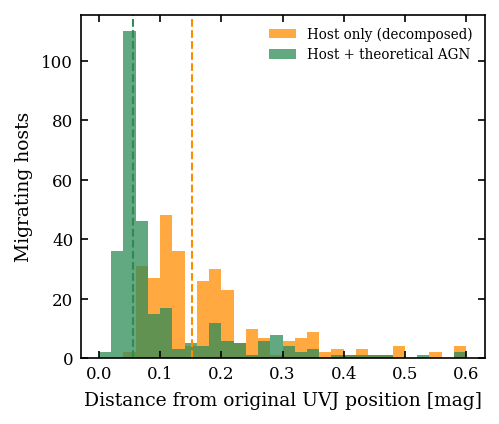

n = 293 migrating hosts; median distance from original position: host-only 0.152 mag -> with AGN added back 0.056 mag
fraction closer to the original after adding the AGN back: 83.6%
Type1 {'all': (0.947, 0.942, 0.953), 'movers': (0.969, 0.949, 0.986), 'n_all': 6509, 'n_mov': 293}
Type2 {'all': (0.944, 0.938, 0.95), 'movers': (0.02, 0.007, 0.038), 'n_all': 6509, 'n_mov': 293}
Matched {'all': (0.961, 0.956, 0.965), 'movers': (0.973, 0.952, 0.99), 'n_all': 6509, 'n_mov': 293}

Per-region agreement (all hosts) and false-positive / false-negative quiescent rates:
Type1: Q:51.8% SF:99.4% D:84.6% | FP=15 FN=239 of 496 true Q
Type2: Q:99.6% SF:95.3% D:78.8% | FP=296 FN=2 of 496 true Q
Matched: Q:68.8% SF:99.2% D:87.4% | FP=17 FN=155 of 496 true Q


In [6]:
def bootstrap_ci(values, n_boot=2000, seed=42):
    v = np.asarray(values, dtype=float); v = v[np.isfinite(v)]
    b = np.random.default_rng(seed).choice(v, size=(n_boot, len(v)), replace=True).mean(axis=1)
    return v.mean(), *np.percentile(b, [2.5, 97.5])

cat = summary_df.merge(df_cig[['ID', 'UV_Full', 'VJ_Full', 'UV_Decomposed', 'VJ_Decomposed']], on='ID', how='left')
cat['cls_full'] = photometry.classify_uvj(cat['VJ_Full'], cat['UV_Full'])
cat['cls_dec'] = photometry.classify_uvj(cat['VJ_Decomposed'], cat['UV_Decomposed'])
cat['mover'] = (cat['cls_full'] != 0) & (cat['cls_dec'] == 0)

METHODS = ['Type1', 'Type2', 'Matched']
res = {}
for m in METHODS:
    ok = cat[f'cls_recombined_{m}'] != -1
    all_hit = (cat.loc[ok, f'cls_recombined_{m}'] == cat.loc[ok, 'cls_full']).astype(float)
    mv = cat[ok & cat['mover']]
    mv_hit = (mv[f'cls_recombined_{m}'] == mv['cls_full']).astype(float)
    res[m] = {'all': bootstrap_ci(all_hit, seed=1), 'movers': bootstrap_ci(mv_hit, seed=2),
              'n_all': int(ok.sum()), 'n_mov': len(mv)}

mv = cat[cat['mover'] & (cat['cls_recombined_Matched'] != -1)].copy()

# Distance in the UVJ plane from each host's ORIGINAL (full-photometry) position
mv['d_host'] = np.hypot(mv['VJ_Decomposed'] - mv['VJ_Full'], mv['UV_Decomposed'] - mv['UV_Full'])
mv['d_back'] = np.hypot(mv['VJ_recombined_Matched'] - mv['VJ_Full'], mv['UV_recombined_Matched'] - mv['UV_Full'])

fig, ax = plt.subplots(figsize=(3.4, 2.9))
edges = np.linspace(0, 0.6, 31)
ax.hist(mv['d_host'].clip(upper=0.6), bins=edges, color='darkorange', alpha=0.75, label='Host only (decomposed)')
ax.hist(mv['d_back'].clip(upper=0.6), bins=edges, color='#2E8B57', alpha=0.75, label='Host + theoretical AGN')
for col, c_ in [('d_host', 'darkorange'), ('d_back', '#2E8B57')]:
    ax.axvline(mv[col].median(), color=c_, ls='--', lw=1)
ax.set_xlabel('Distance from original UVJ position [mag]')
ax.set_ylabel('Migrating hosts')
ax.legend(fontsize=6.5, frameon=False)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'UVJ_CIGALE_recombination_validation.pdf'), bbox_inches='tight')
plt.show()
print(f"n = {len(mv)} migrating hosts; median distance from original position: "
      f"host-only {mv['d_host'].median():.3f} mag -> with AGN added back {mv['d_back'].median():.3f} mag")
print(f"fraction closer to the original after adding the AGN back: {(mv['d_back'] < mv['d_host']).mean():.1%}")

for m in METHODS:
    print(m, {k: (tuple(round(float(a), 3) for a in v) if isinstance(v, tuple) else v) for k, v in res[m].items()})
print(chr(10) + 'Per-region agreement (all hosts) and false-positive / false-negative quiescent rates:')
for m in METHODS:
    ok = cat[f'cls_recombined_{m}'] != -1
    s = ' '.join(f"{n}:{(cat.loc[ok & (cat.cls_full == c), f'cls_recombined_{m}'] == c).mean():.1%}" for c, n in [(0, 'Q'), (1, 'SF'), (2, 'D')])
    fp = (ok & (cat.cls_full != 0) & (cat[f'cls_recombined_{m}'] == 0)).sum(); fn = (ok & (cat.cls_full == 0) & (cat[f'cls_recombined_{m}'] != 0)).sum()
    print(f"{m}: {s} | FP={fp} FN={fn} of {(cat.cls_full == 0).sum()} true Q")